# Forecasting Gas, Electricity, Water consumption
using holts winter, and SARIMA

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

from pmdarima import auto_arima

# Data Exploration

In [2]:
df = pd.read_csv('CA2_Dataset/CA2-Energy-Consumption-Data.csv')

### Check shape, data types, and missing values

In [3]:
print(f"Dataset Shape: {df.shape}")
print(f"\nData Types:\n{df.dtypes}")
print(f"\nMissing Values:\n{df.isnull().sum()}")

Dataset Shape: (397, 4)

Data Types:
DATE                              object
Gas Consumption (tons)           float64
Electricity Consumption (MWh)    float64
Water Consumption (tons)         float64
dtype: object

Missing Values:
DATE                             0
Gas Consumption (tons)           0
Electricity Consumption (MWh)    0
Water Consumption (tons)         0
dtype: int64


### Rename columns

In [4]:
df.columns = ['Date', 'Gas', 'Electricity', 'Water']
df.head()

,Date,Gas,Electricity,Water
0,1/1/1990,18.0,725.1,548.8
1,1/2/1990,15.8,706.7,640.7
2,1/3/1990,17.3,624.5,511.1
3,1/4/1990,18.9,574.7,515.3
4,1/5/1990,22.0,553.2,488.4


### Convert Date column to datetime
Date needs to be in datetime type

In [5]:
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')

# Set Date as index
df = df.set_index('Date')

# Set frequency to Month Start (required for statsmodels)
df = df.asfreq('MS')

# Verify the changes
df.head()

,Gas,Electricity,Water
Date,,,
1990-01-01,18.0,725.1,548.8
1990-02-01,15.8,706.7,640.7
1990-03-01,17.3,624.5,511.1
1990-04-01,18.9,574.7,515.3
1990-05-01,22.0,553.2,488.4


In [6]:
df.describe()

,Gas,Electricity,Water
count,397.000000,397.000000,397.000000
mean,23.785139,888.472544,484.953652
std,4.903452,153.877594,133.908863
min,11.600000,553.200000,44.400000
25%,20.200000,771.100000,384.400000
50%,23.500000,897.800000,487.400000
75%,27.900000,1005.200000,580.200000
max,46.000000,1294.000000,811.000000


In [7]:
# Check the time period covered
print(f"Date Range: {df.index.min()} to {df.index.max()}")
print(f"Total Months: {len(df)}")
print(f"Total Years: {len(df) / 12:.1f}")

Date Range: 1990-01-01 00:00:00 to 2023-01-01 00:00:00
Total Months: 397
Total Years: 33.1


# Exploration Data Analysis

## Time Series Visualization

Before building any models, need to understand what patterns exist in the data. For time series, three main things to look for:

1. **Trend** - is the data going up, down, or staying flat over time?
2. **Seasonality** - are there repeating patterns (like yearly cycles)?
3. **Anomalies** - any weird spikes or drops that don't fit?

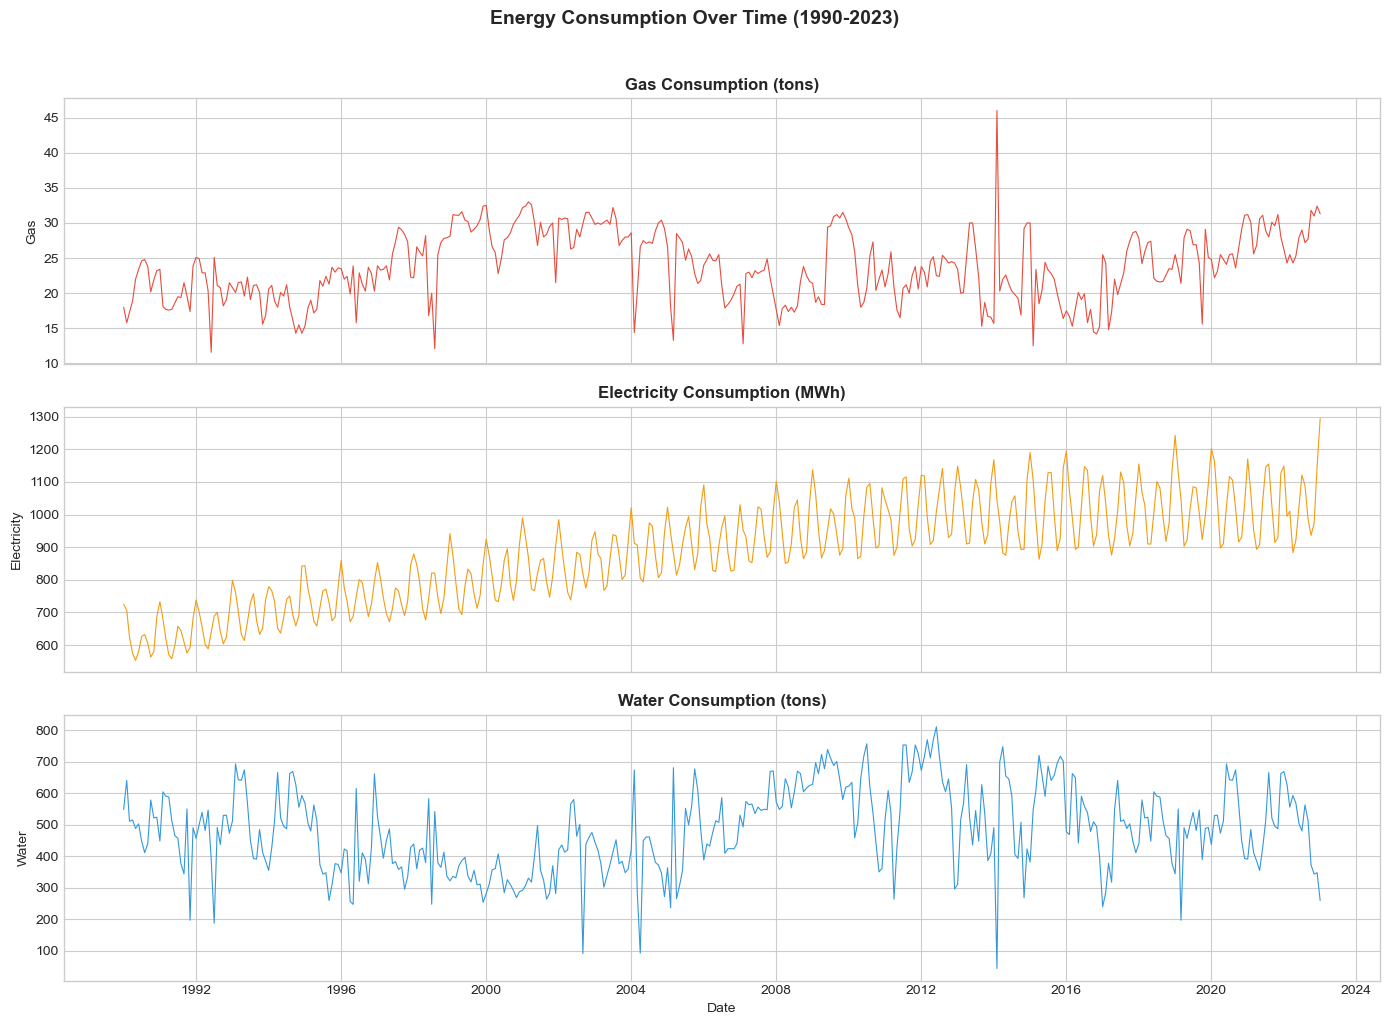

In [8]:
# Plot all three consumption types over time
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

colors = ['#e74c3c', '#f39c12', '#3498db']  # Red, Orange, Blue
titles = ['Gas Consumption (tons)', 'Electricity Consumption (MWh)', 'Water Consumption (tons)']

for ax, col, color, title in zip(axes, df.columns, colors, titles):
    ax.plot(df.index, df[col], color=color, linewidth=0.8)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel(col)

axes[-1].set_xlabel('Date')
plt.suptitle('Energy Consumption Over Time (1990-2023)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Observations from Time Series Plot

**Gas:** Fluctuates between roughly 10-35 tons with no clear long-term trend. Notable spike around 2014 reaching ~45 tons (anomaly). Some seasonal pattern observed.

**Electricity:** Clear upward trend - starts around 600 MWh in 1990, reaches 1000+ MWh by 2023. Growth slows down in recent years. Consistent seasonal pattern throughout.

**Water:** Chaotic - fluctuates a lot with no obvious trend direction. Seasonal pattern present but harder to see due to noise. Notable dips around 2004 and 2014-2015.

## Seasonal Decomposition

Use **seasonal decomposition** to break down each time series into three components:

- **Trend** - underlying long-term direction (smoothed version)
- **Seasonal** - repeating pattern every 12 months
- **Residual** - what's left after removing trend and seasonality

Use period=12 since this is monthly data with yearly seasonality.

For residuals, want them to look like white noise, meaning decomposition successfully captured all meaningful patterns. If residuals still show patterns, something was missed.

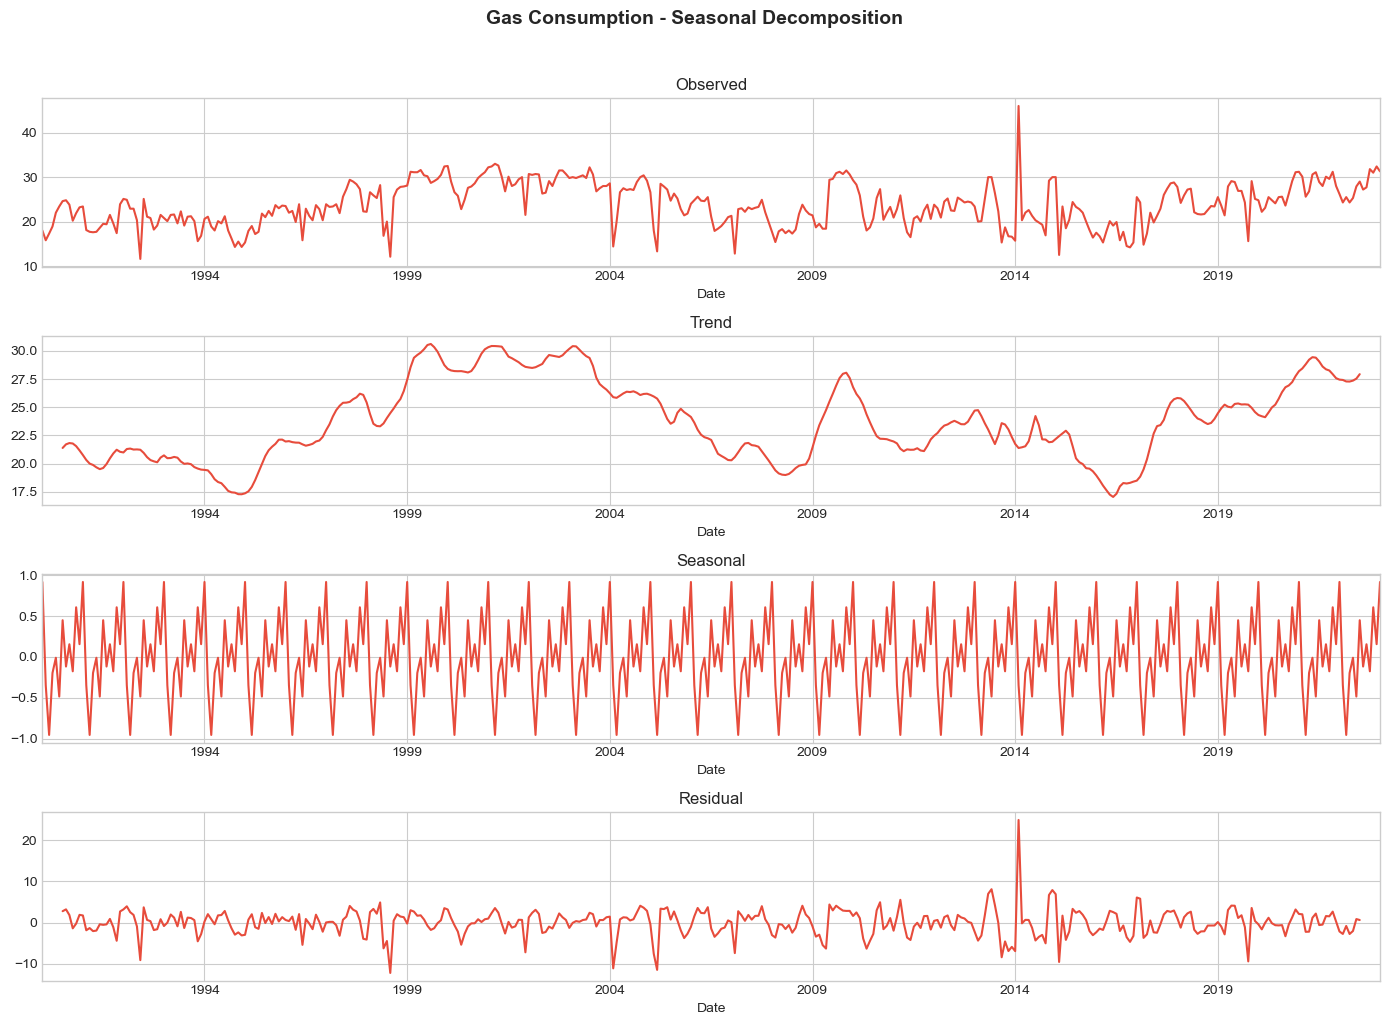

In [9]:
# Decompose Gas consumption
decompose_gas = seasonal_decompose(df['Gas'], model='additive', period=12)
color = '#e74c3c'

fig, axes = plt.subplots(4, 1, figsize=(14, 10))
decompose_gas.observed.plot(ax=axes[0], title='Observed', color=color)
decompose_gas.trend.plot(ax=axes[1], title='Trend', color=color)
decompose_gas.seasonal.plot(ax=axes[2], title='Seasonal', color=color)
decompose_gas.resid.plot(ax=axes[3], title='Residual', color=color )

plt.suptitle('Gas Consumption - Seasonal Decomposition', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Gas Decomposition Analysis

**Trend:** Doesn't follow a simple up or down path. Cycles - rises in late 1990s, drops mid-2000s, rises again around 2010, then stabilizes. Could be related to economic cycles or industrial activity changes.

**Seasonal:** Consistent repeating pattern every 12 months. Wave height stays constant at about ±1 ton -> **additive seasonality** appropriate.

**Residual:** Mostly random noise around zero (good). Large spike around 2014 (+20) corresponds to the anomaly seen earlier - might affect model accuracy.

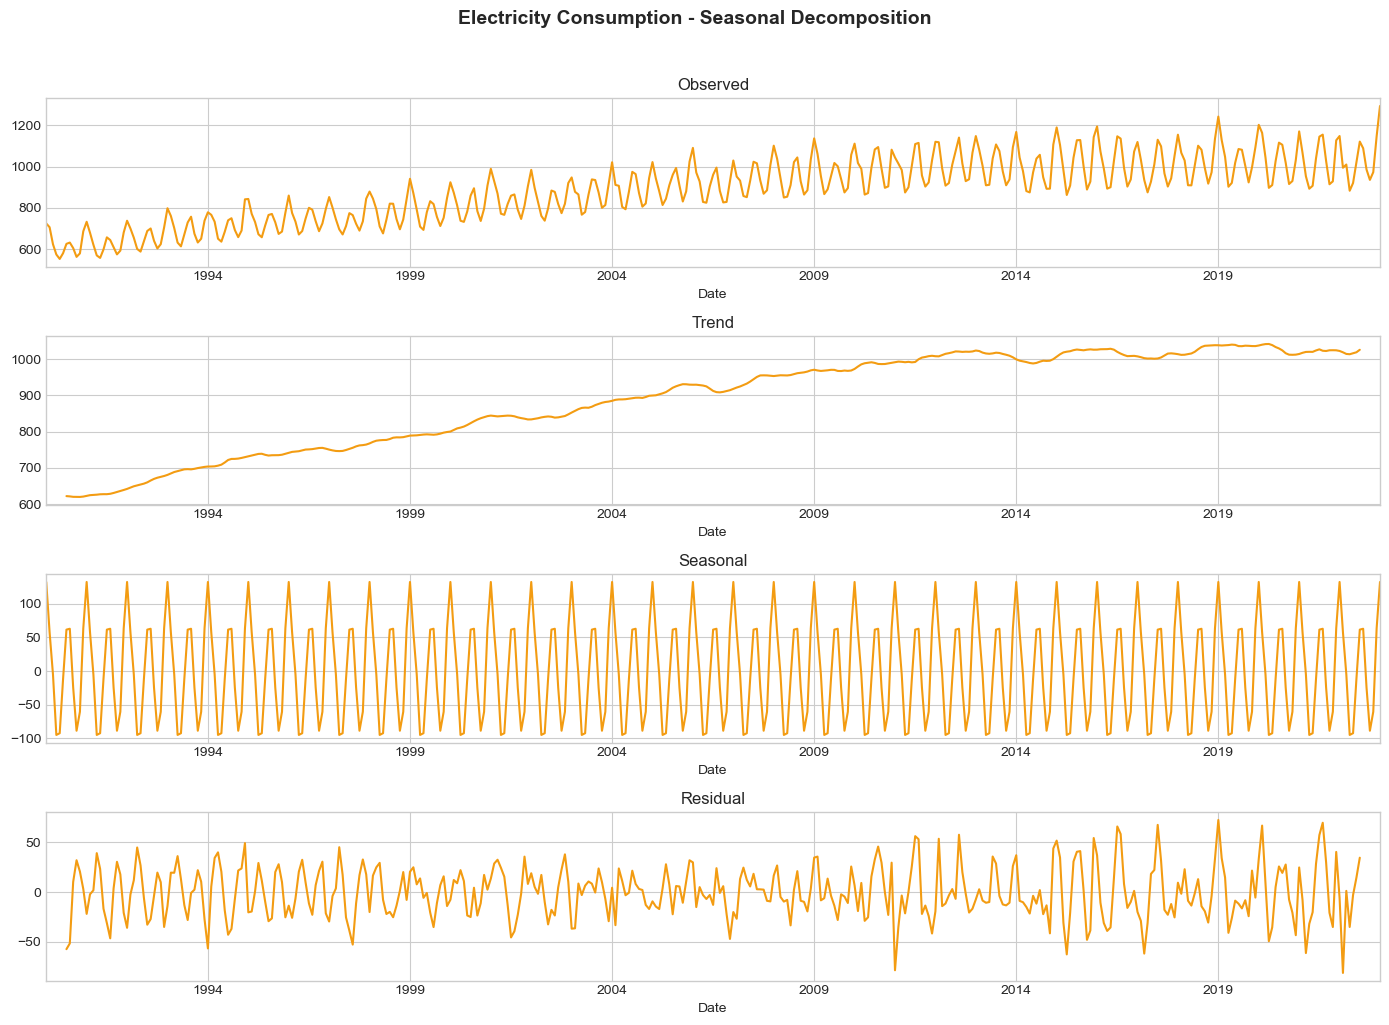

In [10]:
# Decompose Electricity consumption
decompose_elec = seasonal_decompose(df['Electricity'], model='additive', period=12)
color = '#f39c12'

fig, axes = plt.subplots(4, 1, figsize=(14, 10))
decompose_elec.observed.plot(ax=axes[0], title='Observed', color= color)
decompose_elec.trend.plot(ax=axes[1], title='Trend', color=color)
decompose_elec.seasonal.plot(ax=axes[2], title='Seasonal', color=color)
decompose_elec.resid.plot(ax=axes[3], title='Residual', color=color)

plt.suptitle('Electricity Consumption - Seasonal Decomposition', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Electricity Decomposition Analysis

**Trend:** Clear upward trend from ~600 MWh to ~1050 MWh over 33 years. Growth steeper in earlier years (1990-2010), levels off after 2015.

**Seasonal:** Consistent 12 month pattern, amplitude roughly ±100 MWh. Wave height stays constant despite rising trend -> **additive seasonality** appropriate.

**Residual:** Decent white noise - random fluctuations between ±50, no obvious patterns left. Electricity likely the most predictable of the three.

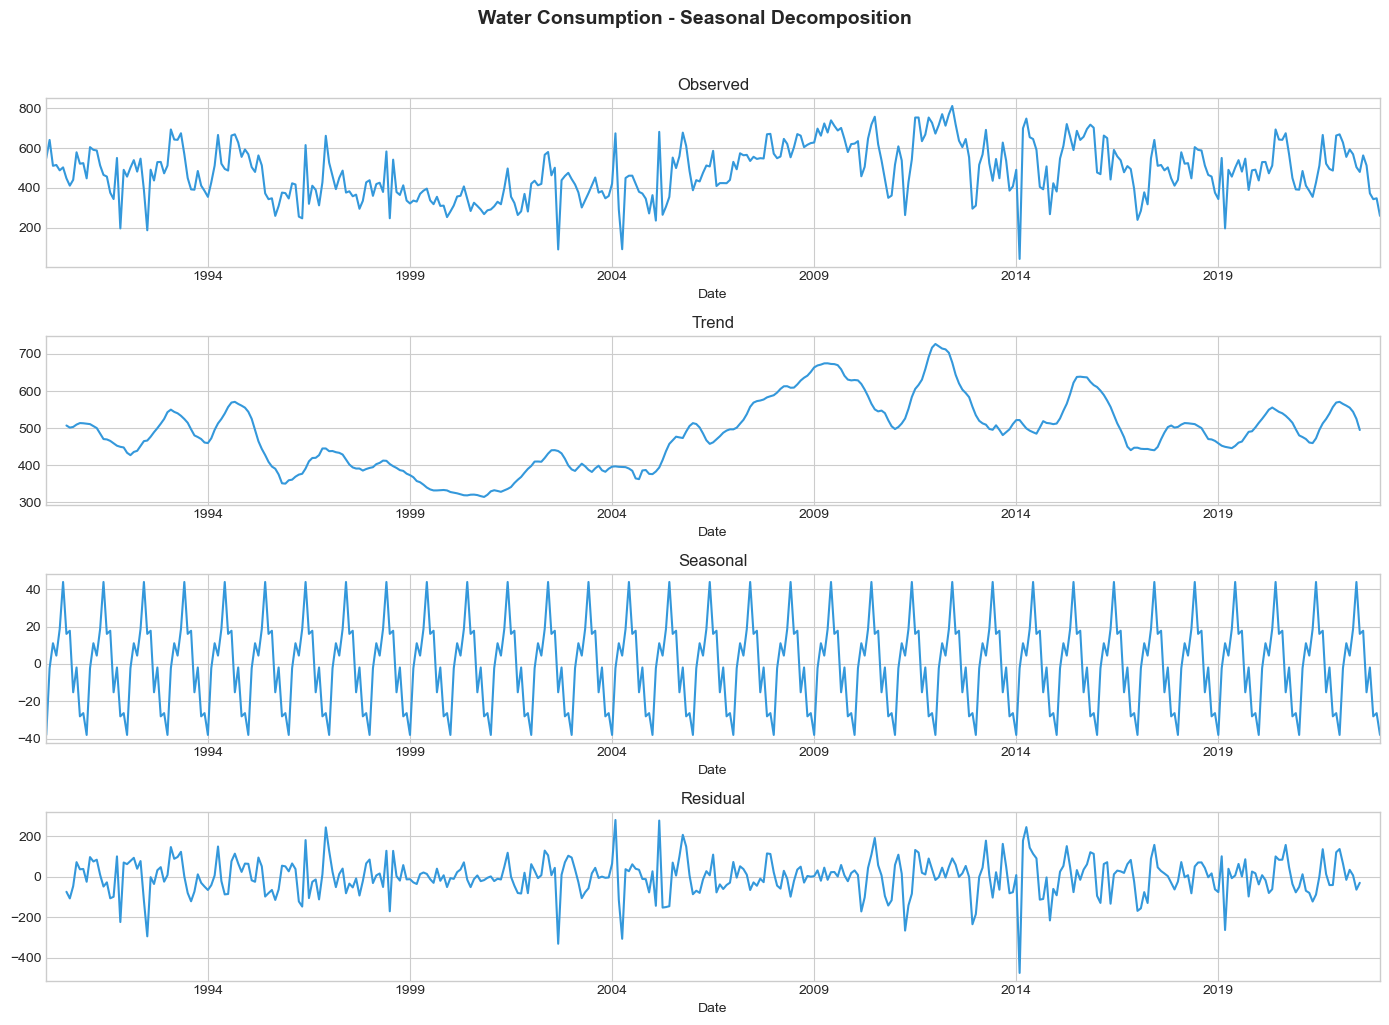

In [11]:
# Decompose Water consumption
decompose_water = seasonal_decompose(df['Water'], model='additive', period=12)
color = '#3498db'

fig, axes = plt.subplots(4, 1, figsize=(14, 10))
decompose_water.observed.plot(ax=axes[0], title='Observed', color=color)
decompose_water.trend.plot(ax=axes[1], title='Trend', color=color)
decompose_water.seasonal.plot(ax=axes[2], title='Seasonal', color=color)
decompose_water.resid.plot(ax=axes[3], title='Residual', color=color)

plt.suptitle('Water Consumption - Seasonal Decomposition', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Water Decomposition Analysis

**Trend:** Most erratic. Drops from ~550 to ~350 tons in early 2000s, shoots up to ~700 around 2010, falls again. Unpredictable trend will make Water hardest to forecast.

**Seasonal:** Clear 12-month pattern, amplitude roughly ±40 tons -> **additive seasonality** appropriate.

**Residual:** Much noisier than Gas or Electricity - swings reaching ±200 tons. Big residuals around 2004 and 2014 suggest external factors that decomposition can't capture. Expecting highest forecast errors for Water.

### ADF (Augmented Dickey-Fuller) Test

Checks whether a time series is stationary:
- p-value < 0.05 -> series IS stationary
- p-value >= 0.05 -> series is NOT stationary

**Note:** ADF mainly detects trend-based non-stationarity, not seasonality. Even if ADF says "stationary", might still need seasonal models.

In [12]:
def adf_test(series, name):
    result = adfuller(series.dropna())
    print(f"=== {name} ===")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    print(f"Stationary: {'Yes' if result[1] < 0.05 else 'No'}")
    print()

adf_test(df['Gas'], 'Gas')
adf_test(df['Electricity'], 'Electricity')
adf_test(df['Water'], 'Water')

=== Gas ===
ADF Statistic: -3.4044
p-value: 0.0108
Stationary: Yes

=== Electricity ===
ADF Statistic: -2.2570
p-value: 0.1862
Stationary: No

=== Water ===
ADF Statistic: -4.6848
p-value: 0.0001
Stationary: Yes



### ADF Test Results

**Gas & Water "stationary"** - ADF only checks for trend-based non-stationarity. No consistent upward/downward trend, so ADF says stationary. Still have seasonality though.

**Electricity non-stationary** - clear upward trend causes mean to shift over time.

**For modeling:** All three still need seasonal models (Holt-Winters, SARIMA) regardless of ADF results. Models have built-in handling for trend and seasonality, no manual transformation needed.

## EDA Summary

| Variable | Trend | Seasonality | Stationarity (ADF) | Noise | Difficulty |
|----------|-------|-------------|-------------------|-------|------------|
| Gas | Cyclical | Strong, 12-month | Stationary | Moderate | Medium |
| Electricity | Strong upward | Strong, 12-month | Non-stationary | Low | Easiest |
| Water | Erratic | Present, 12-month | Stationary | High | Hardest |

**Note on noise:** Residual noise is relative to the data's scale. Electricity residuals of ±50 on values averaging ~850 MWh is only ~6% variation. Gas residuals of ±10 on values averaging ~22 tons is ~45% variation.

Seasonality confirmed through decomposition. All three show clear 12-month cycles.

# Data Preprocessing

## Train/Validation/Test Split

For time series, must split **chronologically**
For time series, **cannot use random split** like regular ML:
- Future data would "leak" into training
- Model would learn patterns it shouldn't know yet
- Real-world forecasting only has access to past data

Split chronologically: Train on oldest data -> Validate on middle -> Test on most recent -> Forecast future.

**Split sizes:**
- **70% train:** Enough data to learn seasonal patterns (need multiple years)
- **15% validation:** Enough months (~60) to tune hyperparameters reliably
- **15% test:** Matches forecast horizon (60 months) - tests realistic scenario

In [13]:
# Calculate split sizes
total_size = len(df)
train_size = int(total_size * 0.70)
val_size = int(total_size * 0.15)
test_size = total_size - train_size - val_size

# Split chronologically
train = df.iloc[:train_size]
val = df.iloc[train_size:train_size + val_size]
test = df.iloc[train_size + val_size:]

# Print split info
print(f"Total: {total_size} months")
print(f"\nTrain: {len(train)} months ({len(train)/total_size*100:.1f}%)")
print(f"  Date range: {train.index.min().strftime('%Y-%m')} to {train.index.max().strftime('%Y-%m')}")
print(f"\nValidation: {len(val)} months ({len(val)/total_size*100:.1f}%)")
print(f"  Date range: {val.index.min().strftime('%Y-%m')} to {val.index.max().strftime('%Y-%m')}")
print(f"\nTest: {len(test)} months ({len(test)/total_size*100:.1f}%)")
print(f"  Date range: {test.index.min().strftime('%Y-%m')} to {test.index.max().strftime('%Y-%m')}")

Total: 397 months

Train: 277 months (69.8%)
  Date range: 1990-01 to 2013-01

Validation: 59 months (14.9%)
  Date range: 2013-02 to 2017-12

Test: 61 months (15.4%)
  Date range: 2018-01 to 2023-01


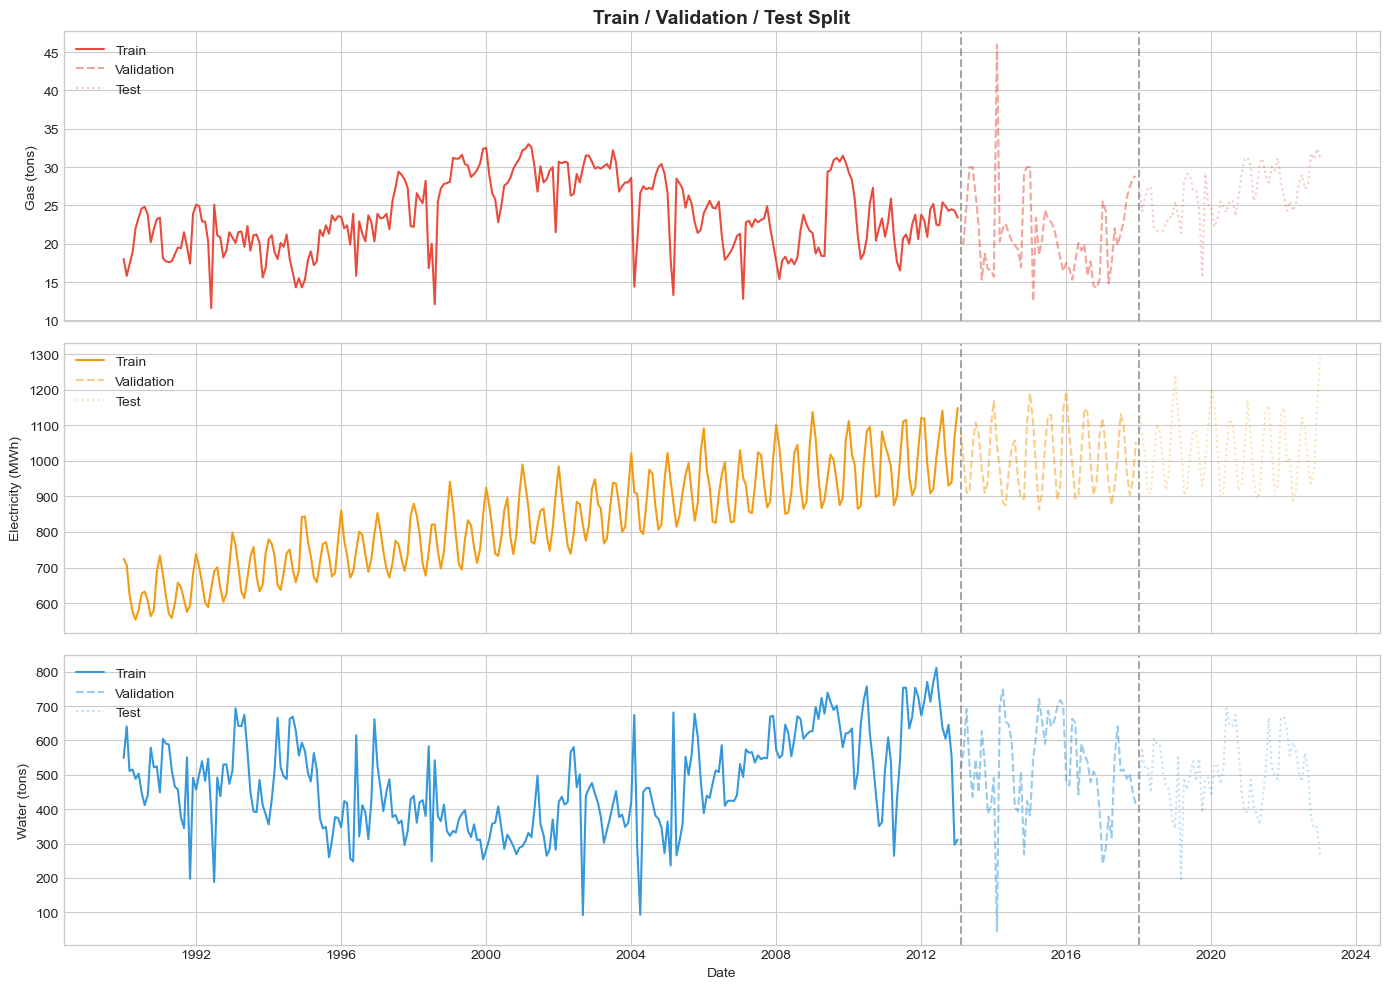

In [14]:
# Visualize train/val/test splits
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

colors = ['#e74c3c', '#f39c12', '#3498db']
titles = ['Gas (tons)', 'Electricity (MWh)', 'Water (tons)']

for ax, col, color, title in zip(axes, df.columns, colors, titles):
    ax.plot(train.index, train[col], color=color, label='Train')
    ax.plot(val.index, val[col], color=color, alpha=0.5, linestyle='--', label='Validation')
    ax.plot(test.index, test[col], color=color, alpha=0.3, linestyle=':', label='Test')
    
    # Add vertical lines to show split points
    ax.axvline(x=val.index[0], color='gray', linestyle='--', alpha=0.7)
    ax.axvline(x=test.index[0], color='gray', linestyle='--', alpha=0.7)
    
    ax.set_ylabel(title)
    ax.legend(loc='upper left')

axes[0].set_title('Train / Validation / Test Split', fontsize=14, fontweight='bold')
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

# Modelling
## Evaluation Metrics

- MAE (Mean Absolute Error): Easy to interpret — average error in original units (tons, MWh). Treats all errors equally.
- RMSE (Root Mean Squared Error): Penalizes large errors more heavily. Useful when big misses are particularly bad.
- MAPE (Mean Absolute Percentage Error): Percentage-based, allows comparison across variables with different scales. A 50 ton error means different things for Water (500 avg) vs Gas (25 avg).

Using MAPE as primary metric since comparing across Gas, Electricity, Water which have very different scales.

## Why Holt-Winters and SARIMA?

Both are standard time series models that handle trend + seasonality:

Holt-Winters (Exponential Smoothing):
- Explicitly models level, trend, seasonal components
- Simple, fast, interpretable
- Good baseline for seasonal data

SARIMA (Seasonal ARIMA):
- More flexible — uses differencing to handle non-stationarity
- Parameters (p,d,q)(P,D,Q,s) give fine control
- Industry standard for time series forecasting

In [15]:
# Evaluation function
def evaluate_model(actual, predicted, model_name="Model"):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    
    return {
        'Model': model_name,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE (%)': round(mape, 2)
    }

## Holt-Winters (Exponential Smoothing)

Holt-Winters handles both trend and seasonality through three components:
- **Level** (α) — baseline value
- **Trend** (β) — direction of change
- **Seasonal** (γ) — repeating patterns

Based on EDA, using `seasonal='add'` since all three variables showed constant seasonal amplitude.

In [16]:
# Store results for comparison
hw_results = []

# Train Holt-Winters for each variable
hw_models = {}
hw_predictions_val = {}

for col in df.columns:
    # Fit on training data
    model = ExponentialSmoothing(
        train[col],
        trend='add',
        seasonal='add',
        seasonal_periods=12
    )
    fitted = model.fit()
    hw_models[col] = fitted
    
    # Predict on validation period
    pred = fitted.forecast(len(val))
    hw_predictions_val[col] = pred
    
    # Evaluate
    result = evaluate_model(val[col], pred, f"HW - {col}")
    hw_results.append(result)
    
# Display results
hw_results_df = pd.DataFrame(hw_results)
print("Holt-Winters Baseline Results (Validation Set)")
print(hw_results_df.to_string(index=False))

Holt-Winters Baseline Results (Validation Set)
           Model    MAE   RMSE  MAPE (%)
        HW - Gas   5.00   6.25     26.07
HW - Electricity  60.35  70.85      6.20
      HW - Water 144.70 175.88     39.51


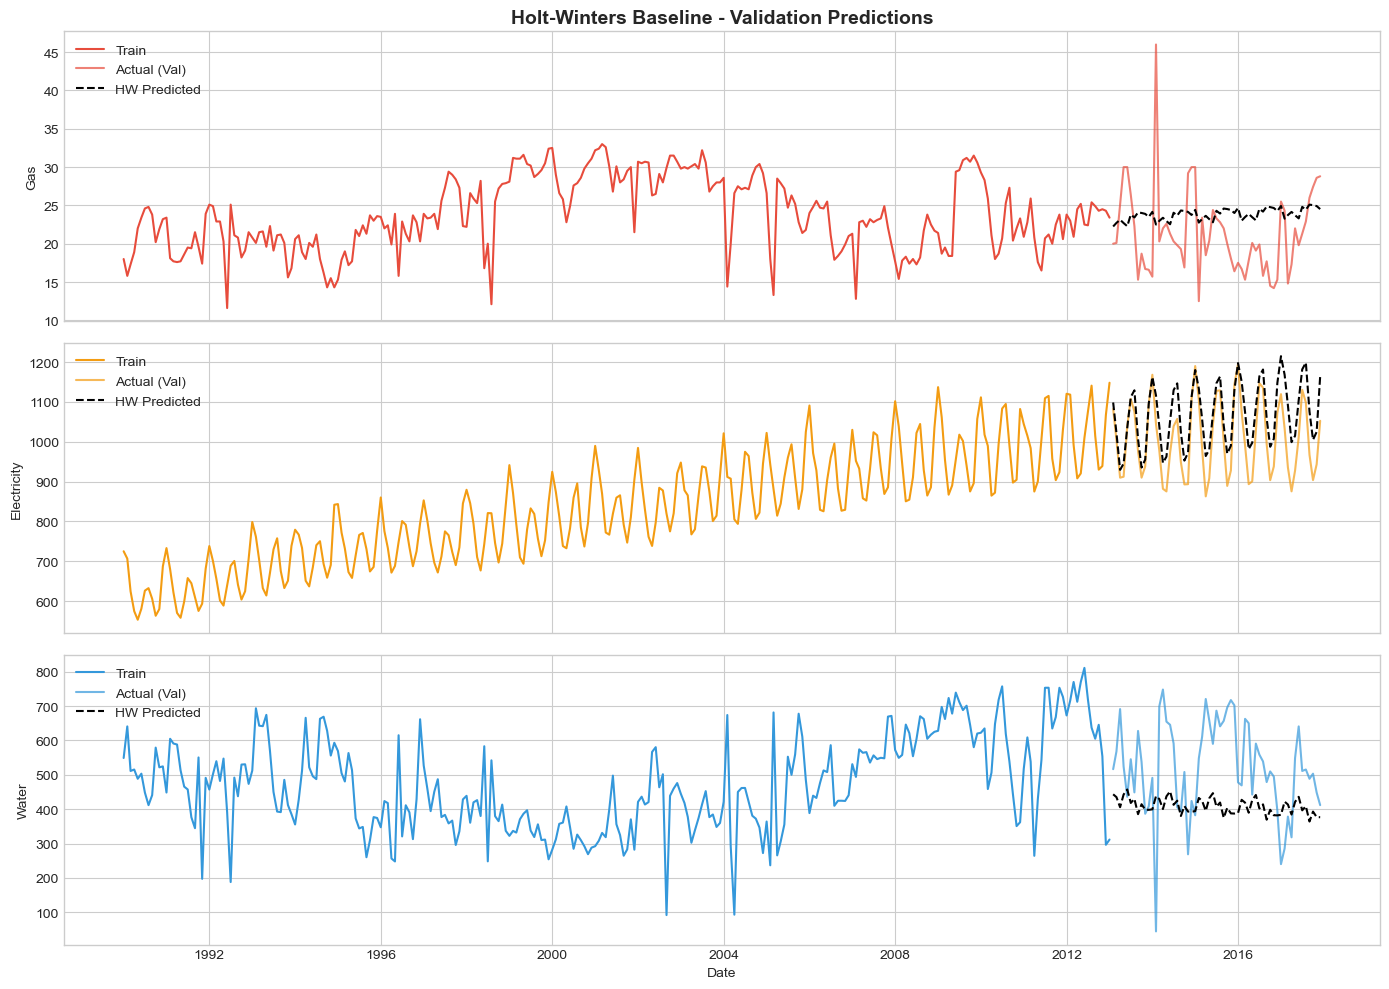

In [17]:
# Plot Holt-Winters predictions vs actual
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

colors = ['#e74c3c', '#f39c12', '#3498db']

for ax, col, color in zip(axes, df.columns, colors):
    ax.plot(train.index, train[col], color=color, label='Train')
    ax.plot(val.index, val[col], color=color, alpha=0.7, label='Actual (Val)')
    ax.plot(val.index, hw_predictions_val[col], color='black', linestyle='--', label='HW Predicted')
    
    ax.set_ylabel(col)
    ax.legend(loc='upper left')

axes[0].set_title('Holt-Winters Baseline - Validation Predictions', fontsize=14, fontweight='bold')
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

## SARIMA (Seasonal ARIMA)

SARIMA has parameters (p,d,q)(P,D,Q,s):
- **(p,d,q)** — non-seasonal: AR order, differencing, MA order
- **(P,D,Q,s)** — seasonal: same but for seasonal component, s=12 for monthly

Starting with common baseline: (1,1,1)(1,1,1,12)
- d=1 handles trend through differencing
- D=1 handles seasonal differencing

In [18]:
# Train SARIMA for each variable
sarima_results = []
sarima_models = {}
sarima_predictions_val = {}

for col in df.columns:
    
    # Fit on training data
    model = SARIMAX(
        train[col],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12)
    )
    fitted = model.fit(disp=False)
    sarima_models[col] = fitted
    
    # Predict on validation period
    pred = fitted.forecast(len(val))
    sarima_predictions_val[col] = pred
    
    # Evaluate
    result = evaluate_model(val[col], pred, f"SARIMA - {col}")
    sarima_results.append(result)

# Display results
sarima_results_df = pd.DataFrame(sarima_results)
print("\nSARIMA Baseline Results (Validation Set)")
print(sarima_results_df.to_string(index=False))


SARIMA Baseline Results (Validation Set)
               Model    MAE   RMSE  MAPE (%)
        SARIMA - Gas   4.92   6.16     25.50
SARIMA - Electricity  60.71  71.04      6.25
      SARIMA - Water 134.75 166.95     50.77


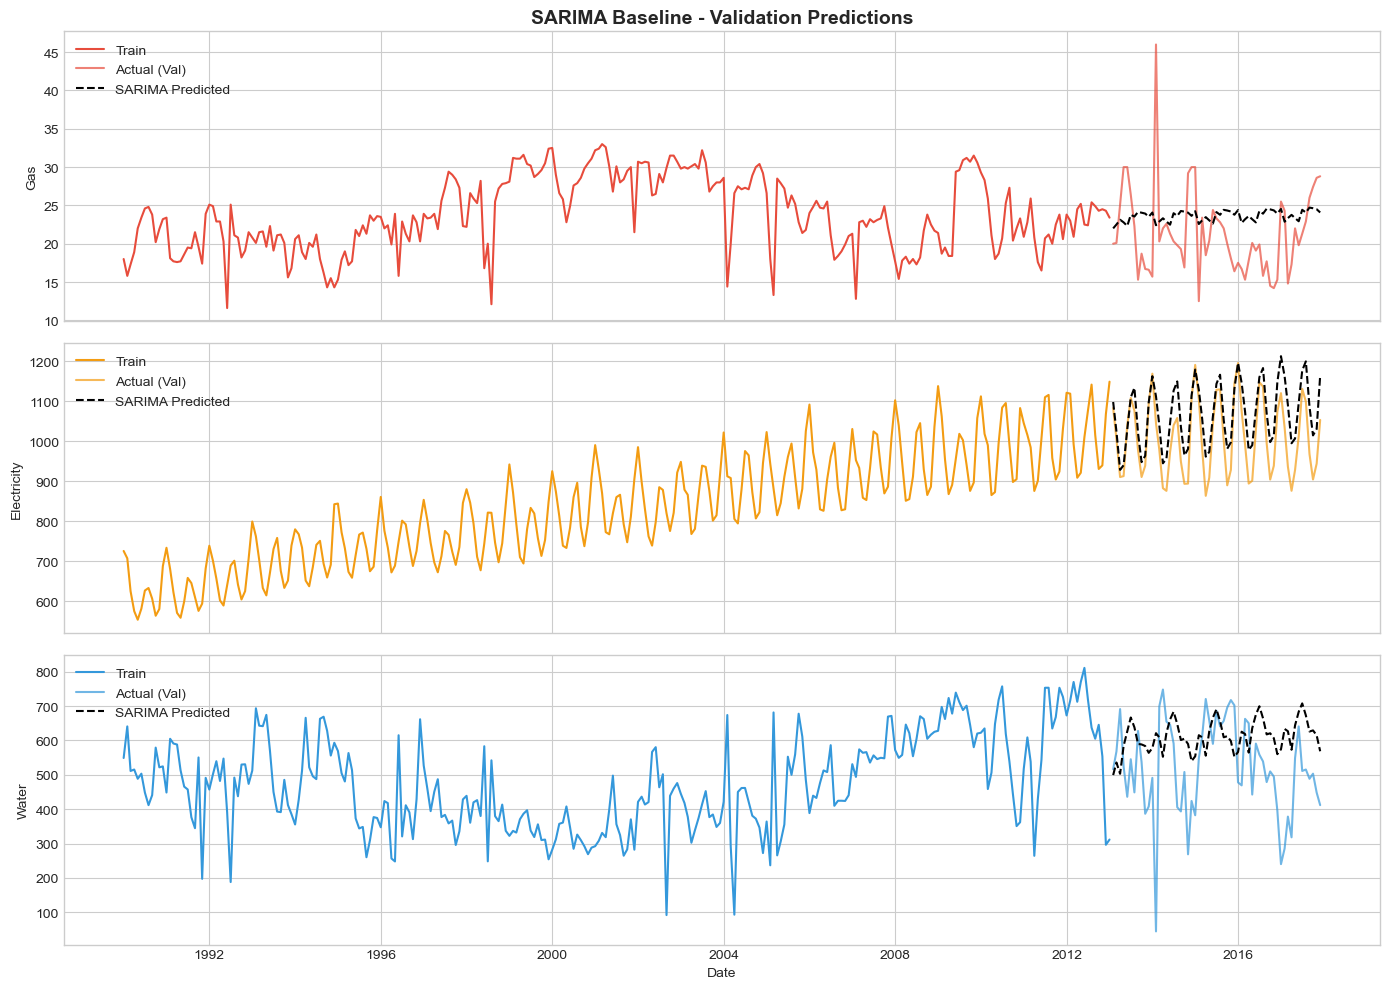

In [19]:
# Plot SARIMA predictions vs actual
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

colors = ['#e74c3c', '#f39c12', '#3498db']

for ax, col, color in zip(axes, df.columns, colors):
    ax.plot(train.index, train[col], color=color, label='Train')
    ax.plot(val.index, val[col], color=color, alpha=0.7, label='Actual (Val)')
    ax.plot(val.index, sarima_predictions_val[col], color='black', linestyle='--', label='SARIMA Predicted')
    
    ax.set_ylabel(col)
    ax.legend(loc='upper left')

axes[0].set_title('SARIMA Baseline - Validation Predictions', fontsize=14, fontweight='bold')
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

In [20]:
# Combine all results
all_baseline_results = pd.DataFrame(hw_results + sarima_results)

# Pivot for easier comparison
print("Baseline Model Comparison (Validation Set)")
print("=" * 60)
print(all_baseline_results.to_string(index=False))

Baseline Model Comparison (Validation Set)
               Model    MAE   RMSE  MAPE (%)
            HW - Gas   5.00   6.25     26.07
    HW - Electricity  60.35  70.85      6.20
          HW - Water 144.70 175.88     39.51
        SARIMA - Gas   4.92   6.16     25.50
SARIMA - Electricity  60.71  71.04      6.25
      SARIMA - Water 134.75 166.95     50.77


# Hyperparameter Tuning

Holt-Winters: Try all combinations of trend and seasonal parameters
- trend: 'add', 'mul', None
- seasonal: 'add', 'mul'

SARIMA: Keep d=1, D=1, s=12 fixed (based on EDA), vary p, q, P, Q slightly
- Try: (1,1,1), (2,1,1), (1,1,2), (0,1,1) for both non-seasonal and seasonal parts

In [21]:
# Holt-Winters hyperparameter tuning
hw_tuning_results = []

trend_options = ['add', 'mul', None]
seasonal_options = ['add', 'mul']

for col in df.columns:
    
    for trend in trend_options:
        for seasonal in seasonal_options:
            try:
                model = ExponentialSmoothing(
                    train[col],
                    trend=trend,
                    seasonal=seasonal,
                    seasonal_periods=12
                )
                fitted = model.fit()
                pred = fitted.forecast(len(val))
                
                mae = mean_absolute_error(val[col], pred)
                rmse = np.sqrt(mean_squared_error(val[col], pred))
                mape = mean_absolute_percentage_error(val[col], pred) * 100
                
                hw_tuning_results.append({
                    'Variable': col,
                    'Trend': trend,
                    'Seasonal': seasonal,
                    'MAE': round(mae, 2),
                    'RMSE': round(rmse, 2),
                    'MAPE (%)': round(mape, 2)
                })
            except:
                # Some combinations may not converge
                pass

hw_tuning_df = pd.DataFrame(hw_tuning_results)
print("Best Holt-Winters Configuration per Variable:")
print("=" * 50)
for col in df.columns:
    best = hw_tuning_df[hw_tuning_df['Variable'] == col].nsmallest(1, 'MAPE (%)').iloc[0]
    print(f"{col}: trend='{best['Trend']}', seasonal='{best['Seasonal']}' → MAPE: {best['MAPE (%)']}%")

Best Holt-Winters Configuration per Variable:
Gas: trend='mul', seasonal='add' → MAPE: 20.35%
Electricity: trend='None', seasonal='mul' → MAPE: 2.53%
Water: trend='None', seasonal='mul' → MAPE: 38.22%


In [22]:
# Find best config for each variable (lowest MAPE)
print("Best Holt-Winters Configuration per Variable:")
print("=" * 60)

best_hw_configs = {}

for col in df.columns:
    col_results = hw_tuning_df[hw_tuning_df['Variable'] == col]
    best_idx = col_results['MAPE (%)'].idxmin()
    best_row = hw_tuning_df.loc[best_idx]
    best_hw_configs[col] = {'trend': best_row['Trend'], 'seasonal': best_row['Seasonal']}
    
    print(f"\n{col}:")
    print(f"  Best config: trend='{best_row['Trend']}', seasonal='{best_row['Seasonal']}'")
    print(f"  MAPE: {best_row['MAPE (%)']}%")

Best Holt-Winters Configuration per Variable:

Gas:
  Best config: trend='mul', seasonal='add'
  MAPE: 20.35%

Electricity:
  Best config: trend='None', seasonal='mul'
  MAPE: 2.53%

Water:
  Best config: trend='None', seasonal='mul'
  MAPE: 38.22%


### SARIMA tuning - vary p, q, P, Q

In [23]:
sarima_tuning_results = []

# Combinations to try (keeping d=1, D=1, s=12 fixed)
orders = [(1,1,1), (2,1,1), (1,1,2), (0,1,1)]
seasonal_orders = [(1,1,1,12), (2,1,1,12), (1,1,2,12), (0,1,1,12)]

for col in df.columns:
    
    for order in orders:
        for seasonal_order in seasonal_orders:
            try:
                model = SARIMAX(
                    train[col],
                    order=order,
                    seasonal_order=seasonal_order
                )
                fitted = model.fit(disp=False)
                pred = fitted.forecast(len(val))
                
                mae = mean_absolute_error(val[col], pred)
                rmse = np.sqrt(mean_squared_error(val[col], pred))
                mape = mean_absolute_percentage_error(val[col], pred) * 100
                
                sarima_tuning_results.append({
                    'Variable': col,
                    'Order': order,
                    'Seasonal Order': seasonal_order,
                    'MAE': round(mae, 2),
                    'RMSE': round(rmse, 2),
                    'MAPE (%)': round(mape, 2)
                })
            except:
                # Some combinations may not converge
                pass

sarima_tuning_df = pd.DataFrame(sarima_tuning_results)
print("Best SARIMA by MAPE (Top 3 per variable):")
print("=" * 60)
for col in df.columns:
    col_results = sarima_tuning_df[sarima_tuning_df['Variable'] == col].nsmallest(3, 'MAPE (%)')
    print(f"\n{col}:")
    print(col_results[['Order', 'Seasonal Order', 'MAPE (%)']].to_string(index=False))

Best SARIMA by MAPE (Top 3 per variable):

Gas:
    Order Seasonal Order  MAPE (%)
(2, 1, 1)  (0, 1, 1, 12)     24.82
(1, 1, 2)  (0, 1, 1, 12)     24.82
(1, 1, 1)  (0, 1, 1, 12)     24.85

Electricity:
    Order Seasonal Order  MAPE (%)
(0, 1, 1)  (2, 1, 1, 12)      5.13
(0, 1, 1)  (1, 1, 2, 12)      5.87
(0, 1, 1)  (0, 1, 1, 12)      6.00

Water:
    Order Seasonal Order  MAPE (%)
(0, 1, 1)  (1, 1, 1, 12)     38.96
(0, 1, 1)  (2, 1, 1, 12)     39.65
(0, 1, 1)  (1, 1, 2, 12)     40.31


In [24]:
# Auto ARIMA for each variable
auto_sarima_results = {}

for col in df.columns:
    print(f"\n{'='*50}")
    print(f"Auto ARIMA for {col}")
    print('='*50)
    
    auto_model = auto_arima(
        train[col],
        seasonal=True,
        m=12,
        max_p=2, max_q=2,
        max_P=1, max_Q=1,
        d=1, D=1,
        stepwise=True,
        trace=False,
        suppress_warnings=True
    )
    
    auto_sarima_results[col] = {
        'model': auto_model,
        'order': auto_model.order,
        'seasonal_order': auto_model.seasonal_order,
        'aic': auto_model.aic()
    }
    
    print(f"\nBest model: SARIMA{auto_model.order}x{auto_model.seasonal_order}")
    print(f"AIC: {auto_model.aic():.2f}")


Auto ARIMA for Gas

Best model: SARIMA(1, 1, 1)x(1, 1, 0, 12)
AIC: 1420.54

Auto ARIMA for Electricity

Best model: SARIMA(1, 1, 1)x(0, 1, 1, 12)
AIC: 2374.33

Auto ARIMA for Water

Best model: SARIMA(1, 1, 1)x(1, 1, 1, 12)
AIC: 3204.56


In [25]:
# Evaluate auto_arima models on validation set
print("\nAuto SARIMA Results on Validation Set:")
print("=" * 60)

auto_sarima_val_results = []

for col in df.columns:
    model_info = auto_sarima_results[col]
    
    # Refit with SARIMAX to get forecast (auto_arima model can also predict directly)
    pred = model_info['model'].predict(n_periods=len(val))
    
    result = evaluate_model(val[col], pred, f"Auto SARIMA - {col}")
    result['Order'] = model_info['order']
    result['Seasonal Order'] = model_info['seasonal_order']
    result['AIC'] = round(model_info['aic'], 2)
    auto_sarima_val_results.append(result)

auto_sarima_val_df = pd.DataFrame(auto_sarima_val_results)
print(auto_sarima_val_df.to_string(index=False))


Auto SARIMA Results on Validation Set:
                    Model    MAE   RMSE  MAPE (%)     Order Seasonal Order     AIC
        Auto SARIMA - Gas   4.73   6.01     24.05 (1, 1, 1)  (1, 1, 0, 12) 1420.54
Auto SARIMA - Electricity  60.37  70.63      6.21 (1, 1, 1)  (0, 1, 1, 12) 2374.33
      Auto SARIMA - Water 134.75 166.95     50.77 (1, 1, 1)  (1, 1, 1, 12) 3204.56


### AIC vs MAPE Comparison

Compared two SARIMA tuning approaches:
- **Manual grid search:** Optimizes MAPE directly on validation set
- **Auto ARIMA:** Optimizes AIC on training data

| Variable | Manual MAPE | Auto ARIMA MAPE | Better Method |
|----------|-------------|-----------------|---------------|
| Gas | 24.82% | 24.05% | Auto ARIMA |
| Electricity | 5.13% | 6.21% | Manual |
| Water | 38.96% | 50.77% | Manual |

**Key insight:** AIC (training fit) doesn't always align with MAPE (forecast accuracy). AIC penalizes complexity but doesn't guarantee best predictions. For forecasting tasks, validating on held-out data (MAPE) is more reliable for model selection.

In [26]:
# Compare best HW vs best SARIMA for each variable
print("Best HW vs Best SARIMA Comparison:")
print("=" * 60)

final_comparison = []

for col in df.columns:
    hw_best = hw_tuning_df[hw_tuning_df['Variable'] == col].nsmallest(1, 'MAPE (%)').iloc[0]
    sarima_best = sarima_tuning_df[sarima_tuning_df['Variable'] == col].nsmallest(1, 'MAPE (%)').iloc[0]
    
    winner = "HW" if hw_best['MAPE (%)'] <= sarima_best['MAPE (%)'] else "SARIMA"
    
    final_comparison.append({
        'Variable': col,
        'HW MAPE (%)': hw_best['MAPE (%)'],
        'SARIMA MAPE (%)': sarima_best['MAPE (%)'],
        'Winner': winner
    })

final_comparison_df = pd.DataFrame(final_comparison)
print(final_comparison_df.to_string(index=False))

Best HW vs Best SARIMA Comparison:
   Variable  HW MAPE (%)  SARIMA MAPE (%) Winner
        Gas        20.35            24.82     HW
Electricity         2.53             5.13     HW
      Water        38.22            38.96     HW


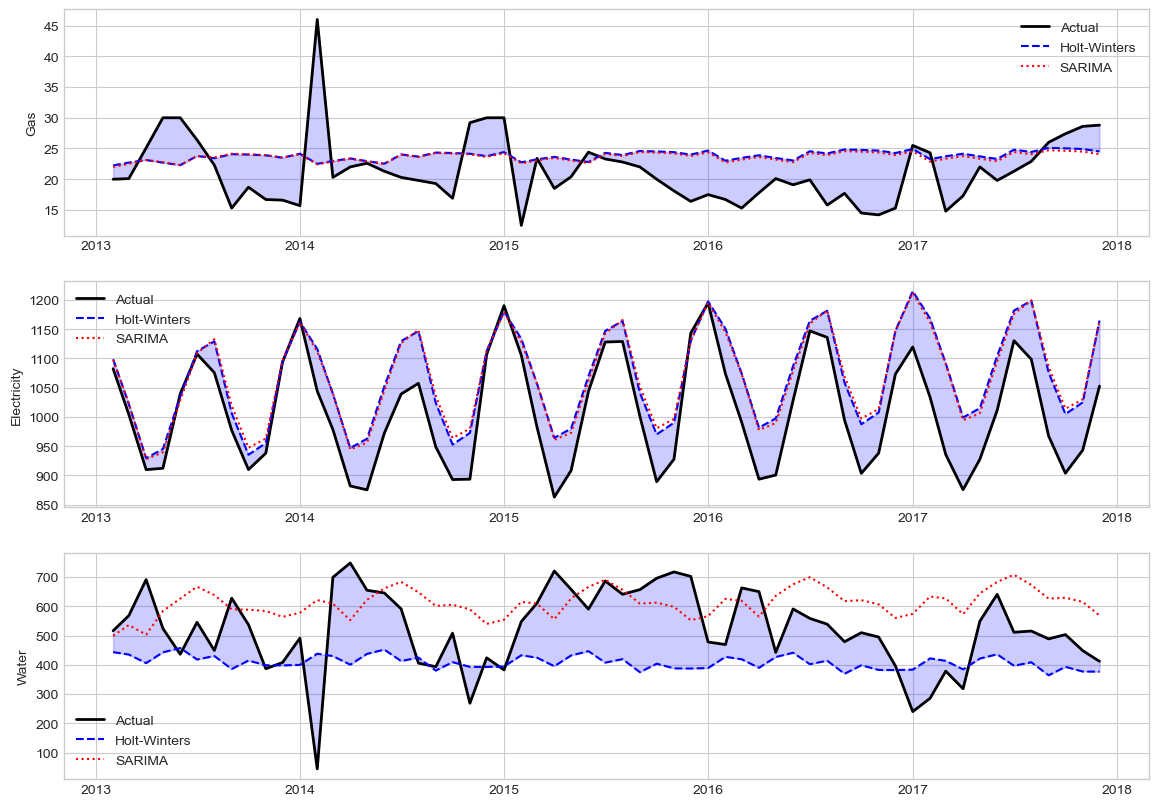

In [27]:
# After your existing validation predictions
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
for ax, col in zip(axes, df.columns):
    ax.plot(val.index, val[col], 'k-', label='Actual', linewidth=2)
    ax.plot(val.index, hw_predictions_val[col], 'b--', label='Holt-Winters')
    ax.plot(val.index, sarima_predictions_val[col], 'r:', label='SARIMA')
    ax.fill_between(val.index, val[col], hw_predictions_val[col], alpha=0.2, color='blue')
    ax.set_ylabel(col)
    ax.legend()

### Visual differences between HW and SARIMA

- For Gas and Electricity, HW and SARIMA produce nearly identical predictions visually even though gas shows 4.5% MAPE difference (20.35% vs 24.82%). Small absolute errors (1-2 tons) are invisible on the plot scale but compound across 59 months.
- The difference shows in Water: SARIMA (red) systematically overestimates while HW (blue) stays closer to actuals. This, combined with lower MAPE, supports choosing Holt-Winters.

### Tuning Summary

| Variable | Best Model | Trend | Seasonal | Baseline MAPE | Tuned MAPE | Improvement |
|----------|------------|-------|----------|---------------|------------|-------------|
| Gas | Holt-Winters | mul | add | 26.07% | 20.35% | -5.72% |
| Electricity | Holt-Winters | None | mul | 6.20% | 2.53% | -3.67% |
| Water | Holt-Winters | None | mul | 39.51% | 38.22% | -1.29% |

**Observations:**
- Holt-Winters outperformed SARIMA for all three variables
- Multiplicative seasonality performed better than additive for Electricity and Water (contrary to EDA visual analysis), this shows importance of actual testing
- Electricity and Water don't need explicit trend component, the leveling off observed in EDA means no trend works better for forecasting
- Tuning gave significant improvement for Gas and Electricity
- Water improved slightly but still has high error due to inherent data volatility

# Test Set Evaluation

Now evaluate the best models on the **test set** — data the model has never seen during training or tuning. This gives an unbiased estimate of real-world performance.

Using the best Holt-Winters configurations from tuning:
- **Gas:** trend='mul', seasonal='add'
- **Electricity:** trend=None, seasonal='mul'
- **Water:** trend=None, seasonal='mul'

In [28]:
# Combine train and validation for final training
train_val = pd.concat([train, val])

print(f"Training data: {len(train_val)} months ({train_val.index.min().strftime('%Y-%m')} to {train_val.index.max().strftime('%Y-%m')})")
print(f"Test data: {len(test)} months ({test.index.min().strftime('%Y-%m')} to {test.index.max().strftime('%Y-%m')})")

# Train best HW models and evaluate on test set
test_results = []
best_models = {}
test_predictions = {}

for col in df.columns:
    config = best_hw_configs[col]
    
    model = ExponentialSmoothing(
        train_val[col],
        trend=config['trend'],
        seasonal=config['seasonal'],
        seasonal_periods=12
    )
    fitted = model.fit()
    best_models[col] = fitted
    
    # Predict on test period
    pred = fitted.forecast(len(test))
    test_predictions[col] = pred
    
    # Evaluate
    result = evaluate_model(test[col], pred, col)
    test_results.append(result)

test_results_df = pd.DataFrame(test_results)
print("\nTest Set Results:")
print(test_results_df.to_string(index=False))

Training data: 336 months (1990-01 to 2017-12)
Test data: 61 months (2018-01 to 2023-01)

Test Set Results:
      Model   MAE   RMSE  MAPE (%)
        Gas  2.91   3.62     11.50
Electricity 34.26  46.50      3.20
      Water 80.88 104.01     17.55


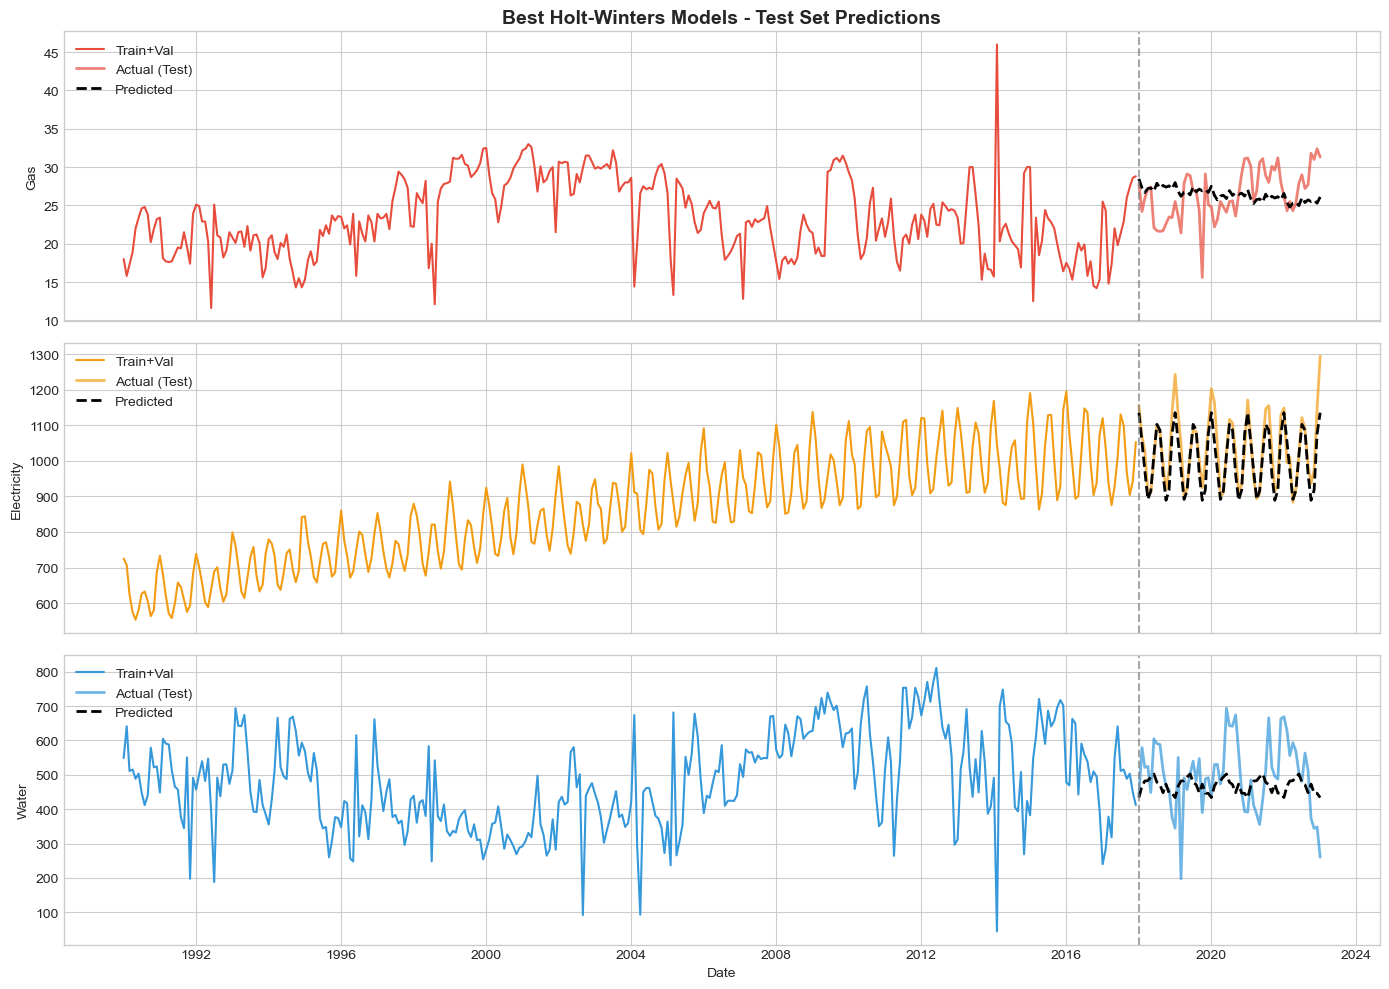

In [29]:
# Plot test predictions vs actual
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

colors = ['#e74c3c', '#f39c12', '#3498db']

for ax, col, color in zip(axes, df.columns, colors):
    ax.plot(train_val.index, train_val[col], color=color, label='Train+Val')
    ax.plot(test.index, test[col], color=color, alpha=0.7, linewidth=2, label='Actual (Test)')
    ax.plot(test.index, test_predictions[col], color='black', linestyle='--', linewidth=2, label='Predicted')
    
    ax.axvline(x=test.index[0], color='gray', linestyle='--', alpha=0.7)
    ax.set_ylabel(col)
    ax.legend(loc='upper left')

axes[0].set_title('Best Holt-Winters Models - Test Set Predictions', fontsize=14, fontweight='bold')
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

In [30]:
# Compare validation vs test performance
print("Validation vs Test Performance Comparison:")
print("=" * 60)

# Get best validation MAPE per variable (simpler approach)
comparison_data = []
for col in df.columns:
    val_mape = hw_tuning_df[hw_tuning_df['Variable'] == col]['MAPE (%)'].min()
    test_mape = test_results_df[test_results_df['Model'] == col]['MAPE (%)'].values[0]
    
    comparison_data.append({
        'Variable': col,
        'Val MAPE (%)': val_mape,
        'Test MAPE (%)': test_mape,
        'Difference': round(test_mape - val_mape, 2)
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

Validation vs Test Performance Comparison:
   Variable  Val MAPE (%)  Test MAPE (%)  Difference
        Gas         20.35          11.50       -8.85
Electricity          2.53           3.20        0.67
      Water         38.22          17.55      -20.67


In [31]:
# Recreate best SARIMA configs from tuning results
best_sarima_configs = {}

for col in df.columns:
    col_results = sarima_tuning_df[sarima_tuning_df['Variable'] == col]
    best_idx = col_results['MAPE (%)'].idxmin()
    best_row = sarima_tuning_df.loc[best_idx]
    best_sarima_configs[col] = {'order': best_row['Order'], 'seasonal_order': best_row['Seasonal Order']}

In [32]:
# Test best SARIMA models on test set for comparison
sarima_test_results = []
sarima_test_predictions = {}

for col in df.columns:
    config = best_sarima_configs[col]
    
    model = SARIMAX(
        train_val[col],
        order=config['order'],
        seasonal_order=config['seasonal_order']
    )
    fitted = model.fit(disp=False)
    
    pred = fitted.forecast(len(test))
    sarima_test_predictions[col] = pred
    
    result = evaluate_model(test[col], pred, col)
    sarima_test_results.append(result)

sarima_test_results_df = pd.DataFrame(sarima_test_results)

# Compare HW vs SARIMA on test set
print("Test Set: Holt-Winters vs SARIMA")
print("=" * 60)

for col in df.columns:
    hw_mape = test_results_df[test_results_df['Model'] == col]['MAPE (%)'].values[0]
    sarima_mape = sarima_test_results_df[sarima_test_results_df['Model'] == col]['MAPE (%)'].values[0]
    winner = "HW" if hw_mape <= sarima_mape else "SARIMA"
    
    print(f"{col}: HW={hw_mape}% | SARIMA={sarima_mape}% | Winner: {winner}")

Test Set: Holt-Winters vs SARIMA
Gas: HW=11.5% | SARIMA=13.32% | Winner: HW
Electricity: HW=3.2% | SARIMA=4.02% | Winner: HW
Water: HW=17.55% | SARIMA=17.98% | Winner: HW


### Analyze Period Characteristics

Comparing volatility between periods to understand performance differences.

In [33]:
print("Volatility Comparison (Standard Deviation):")
print("=" * 60)

for col in df.columns:
    val_std = val[col].std()
    test_std = test[col].std()
    print(f"\n{col}:")
    print(f"  Validation std: {val_std:.2f}")
    print(f"  Test std: {test_std:.2f}")
    print(f"  Test is {'less' if test_std < val_std else 'more'} volatile")

Volatility Comparison (Standard Deviation):

Gas:
  Validation std: 5.63
  Test std: 3.30
  Test is less volatile

Electricity:
  Validation std: 94.36
  Test std: 98.78
  Test is more volatile

Water:
  Validation std: 137.33
  Test std: 102.41
  Test is less volatile


### Volatility Analysis

| Variable | Val Std | Test Std | Test Period |
|----------|---------|----------|-------------|
| Gas | 5.63 | 3.30 | 41% less volatile |
| Electricity | 94.36 | 98.78 | Slightly more volatile |
| Water | 137.33 | 102.41 | 25% less volatile |

**Why validation MAPE was higher:**
- Validation period (2013-2017) contained Gas anomaly (2014 spike) and higher Water volatility
- Test period (2018-2023) was calmer
- This explains why test MAPE improved for Gas and Water
- Model didn't overfit - validation was just a harder period

### Final Model Comparison (Test Set)

| Variable | HW MAPE | SARIMA MAPE | Winner |
|----------|---------|-------------|--------|
| Gas | 11.50% | 13.32% | Holt-Winters |
| Electricity | 3.20% | 4.02% | Holt-Winters |
| Water | 17.55% | 17.98% | Holt-Winters |

Use Holt-Winters Exponential Smoothing for all three variables for final forecasting.
- HW wins Gas and Electricity
- Water difference is negligible (0.43%)
- Simpler to use one model type for all variables
- HW also trains faster

# Final Forecast

Retrain Holt-Winters on **all available data** (train + validation + test), then forecast **60 months** into the future.

Using best configurations:
- **Gas:** trend='mul', seasonal='add'
- **Electricity:** trend=None, seasonal='mul'
- **Water:** trend=None, seasonal='mul'

In [34]:
# Retrain on all data with confidence intervals
final_models = {}
forecasts = {}
forecast_cis = {}  # Store confidence intervals
forecast_horizon = 60

for col in df.columns:
    config = best_hw_configs[col]
    
    model = ExponentialSmoothing(
        df[col],
        trend=config['trend'],
        seasonal=config['seasonal'],
        seasonal_periods=12
    )
    fitted = model.fit()
    final_models[col] = fitted
    
    # Point forecast
    forecast = fitted.forecast(forecast_horizon)
    forecasts[col] = forecast
    
    # Simulate for confidence intervals (1000 simulations)
    simulations = fitted.simulate(nsimulations=forecast_horizon, repetitions=1000, anchor='end')
    lower = simulations.quantile(0.025, axis=1)  # 2.5th percentile
    upper = simulations.quantile(0.975, axis=1)  # 97.5th percentile
    
    forecast_cis[col] = {'lower': lower, 'upper': upper}
    
    print(f"{col}: Forecasted {forecast_horizon} months with 95% CI")

# Create forecast dataframe
forecast_df = pd.DataFrame(forecasts)
print(f"\nForecast period: {forecast_df.index.min().strftime('%Y-%m')} to {forecast_df.index.max().strftime('%Y-%m')}")
forecast_df.head(10)

Gas: Forecasted 60 months with 95% CI
Electricity: Forecasted 60 months with 95% CI
Water: Forecasted 60 months with 95% CI

Forecast period: 2023-02 to 2028-01


,Gas,Electricity,Water
2023-02-01,30.235574,1176.953167,358.329048
2023-03-01,29.635155,1097.584992,356.328178
2023-04-01,30.375677,985.548021,362.153200
2023-05-01,30.612442,989.723789,366.704888
2023-06-01,30.154256,1090.411169,380.006668
2023-07-01,30.967363,1183.801057,365.650935
2023-08-01,30.339468,1184.915102,365.403058
2023-09-01,30.575586,1073.056773,347.889003
2023-10-01,30.334249,992.388261,352.372835
2023-11-01,31.016155,1026.644749,334.487921


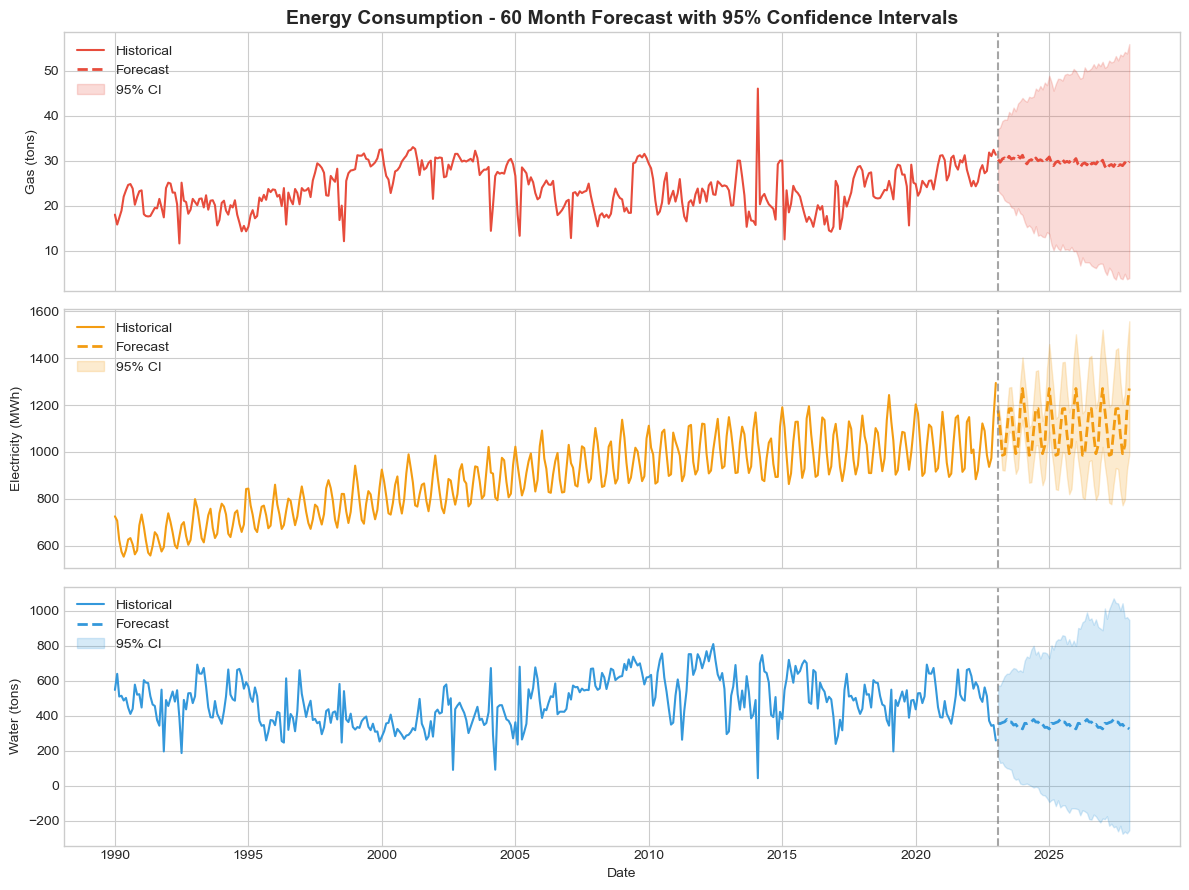

In [37]:
# Plot historical data + forecasts with confidence intervals
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

colors = ['#e74c3c', '#f39c12', '#3498db']
titles = ['Gas (tons)', 'Electricity (MWh)', 'Water (tons)']

for ax, col, color, title in zip(axes, df.columns, colors, titles):
    # Historical data
    ax.plot(df.index, df[col], color=color, label='Historical')
    
    # Forecast
    ax.plot(forecast_df.index, forecast_df[col], color=color, linestyle='--', linewidth=2, label='Forecast')
    
    # 95% Confidence interval (using actual simulated CI)
    ax.fill_between(forecast_df.index, 
                    forecast_cis[col]['lower'], 
                    forecast_cis[col]['upper'], 
                    alpha=0.2, color=color, label='95% CI')
    
    # Vertical line at forecast start
    ax.axvline(x=forecast_df.index[0], color='gray', linestyle='--', alpha=0.7)
    
    ax.set_ylabel(title)
    ax.legend(loc='upper left')

axes[0].set_title('Energy Consumption - 60 Month Forecast with 95% Confidence Intervals', fontsize=14, fontweight='bold')
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

In [36]:
# Summary of forecasted values
print("Forecast Summary (Next 60 Months):")
print("=" * 60)

for col in df.columns:
    historical_mean = df[col].mean()
    forecast_mean = forecast_df[col].mean()
    forecast_min = forecast_df[col].min()
    forecast_max = forecast_df[col].max()
    
    print(f"\n{col}:")
    print(f"  Historical mean: {historical_mean:.2f}")
    print(f"  Forecast mean: {forecast_mean:.2f}")
    print(f"  Forecast range: {forecast_min:.2f} - {forecast_max:.2f}")

Forecast Summary (Next 60 Months):

Gas:
  Historical mean: 23.79
  Forecast mean: 29.77
  Forecast range: 28.17 - 31.20

Electricity:
  Historical mean: 888.47
  Forecast mean: 1104.50
  Forecast range: 985.55 - 1270.47

Water:
  Historical mean: 484.95
  Forecast mean: 354.25
  Forecast range: 326.00 - 380.01


### Forecast Observations

**Gas:**
- Stable seasonal pattern continuing around 28-31 tons
- Wide 95% CI (expanding from ~15-45 tons to ~5-55 tons) reflects uncertainty growth over longer horizons
- The 2014 spike contributes to wider confidence bands

**Electricity:**
- No trend component (trend=None): forecast maintains current level with seasonal oscillation
- Stable around 1000-1200 MWh range with relatively narrow CI
- Most reliable forecast given lowest MAPE (3.20%)
- CI stays within plausible range throughout forecast period

**Water:**
- Seasonal pattern maintained around 350-380 tons
- Widest relative CI of all three, lower bound goes negative by end of forecast period
- Negative values are physically impossible, highlighting model limitation for highly volatile data
- Least reliable

**Limitations:**
- Forecasts assume historical patterns continue like external factors (policy changes, economic shifts, climate) not accounted for
- Confidence intervals widen over time, reflecting increasing uncertainty
- Water and Gas CIs include unrealistic values (negative consumption), suggesting log transformation or constrained models might be more appropriate
- Models capture seasonal patterns well but can't predict anomalies

# Conclusion

## Summary

Built time series forecasting models to predict Gas, Electricity, and Water consumption for the next 60 months using Holt-Winters and SARIMA.

## Workflow

1. **EDA:** Analyzed trends, seasonality, and stationarity (ADF test)
2. **Preprocessing:** Chronological train/validation/test split (70/15/15)
3. **Modeling:** Built baseline Holt-Winters and SARIMA models
4. **Tuning:** Hyperparameter tuning — thorough for HW, light for SARIMA, plus auto_arima
5. **Evaluation:** Compared models on validation and test sets
6. **Forecasting:** Retrained best models on all data, forecasted 60 months

## Key Findings

**EDA Insights:**
- All three variables show 12-month seasonality
- Electricity has strong upward trend (leveling off recently)
- Gas has cyclical trend with no clear direction
- Water is highly volatile with erratic trend
- Multiplicative seasonality outperformed additive for Electricity and Water (contrary to initial visual analysis)

**Model Performance (Test Set):**

| Variable | Best Model | MAPE | Interpretation |
|----------|------------|------|----------------|
| Gas | Holt-Winters | 11.50% | ~±2.9 tons average error |
| Electricity | Holt-Winters | 3.20% | ~±34 MWh average error |
| Water | Holt-Winters | 17.55% | ~±81 tons average error |

**Best Configurations:**
- Gas: trend='mul', seasonal='add'
- Electricity: trend=None, seasonal='mul'
- Water: trend=None, seasonal='mul'

## Model Comparison

Holt-Winters outperformed SARIMA for Gas and Electricity. Water was essentially tied (17.55% vs 17.98%). Chose Holt-Winters for all three for consistency and simplicity.

## Limitations

- Forecasts assume historical patterns continue
- External factors (policy, economic, climate changes) not accounted for
- Water inherently difficult to predict due to high volatility
- Anomalies (Gas 2014 spike) can affect model training
- Longer horizons have increasing uncertainty

## Recommendations

- **Electricity:** Forecast reliable - can be used for planning
- **Gas:** Moderate reliability - use with some buffer
- **Water:** Treat forecasts with caution - high historical volatility means actual values may differ significantly